In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

file_path = r'C:\Users\fox77\Downloads\opendata-02-entrant.csv'

df_entrant = pd.read_csv(
    file_path,
    sep=';',
    encoding='utf-8'
)

print("Розмір датасету:", df_entrant.shape)
display(df_entrant.head())
df_entrant.info()

Розмір датасету: (289311, 17)


,year,qualification_name,speciality_code,speciality_name,specialization_name,region_name_u,university_name,university_id,university_parent_id,university_financing_type_name,university_governance_type_name,entrant_fulltime_budget,entrant_fulltime_contract,entrant_partime_budget,entrant_partime_contract,entrant_evening_budget,entrant_evening_contract
0,2015,Бакалавр,012,Дошкільна освіта,NaN,Вінницька область,Вінницький державний педагогічний університет ...,252,NaN,Державна,Міністерство освіти і науки України,1,2,0,0,0,0
1,2015,Бакалавр,012,Дошкільна освіта,NaN,Волинська область,"Комунальний заклад вищої освіти ""Луцький педаг...",624,NaN,Комунальна,Управління освіти і науки Волинської обласної ...,1,0,1,0,0,0
2,2015,Бакалавр,012,Дошкільна освіта,NaN,Житомирська область,Житомирський державний університет імені Івана...,109,NaN,Державна,Міністерство освіти і науки України,0,1,0,0,0,0
3,2015,Бакалавр,012,Дошкільна освіта,NaN,Закарпатська область,"""ЗАКАРПАТСЬКИЙ УГОРСЬКИЙ УНІВЕРСИТЕТ ІМЕНІ ФЕР...",95,NaN,Приватна,Без підпорядкування,0,0,0,1,0,0
4,2015,Бакалавр,012,Дошкільна освіта,NaN,Запорізька область,Мелітопольський державний педагогічний універс...,78,NaN,Державна,Міністерство освіти і науки України,1,0,1,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 289311 entries, 0 to 289310
Data columns (total 17 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   year                             289311 non-null  int64  
 1   qualification_name               289311 non-null  str    
 2   speciality_code                  289311 non-null  str    
 3   speciality_name                  289311 non-null  str    
 4   specialization_name              39878 non-null   str    
 5   region_name_u                    289028 non-null  str    
 6   university_name                  289311 non-null  str    
 7   university_id                    289311 non-null  int64  
 8   university_parent_id             61637 non-null   float64
 9   university_financing_type_name   289311 non-null  str    
 10  university_governance_type_name  289311 non-null  str    
 11  entrant_fulltime_budget          289311 non-null  int64  
 12  entrant_fullt

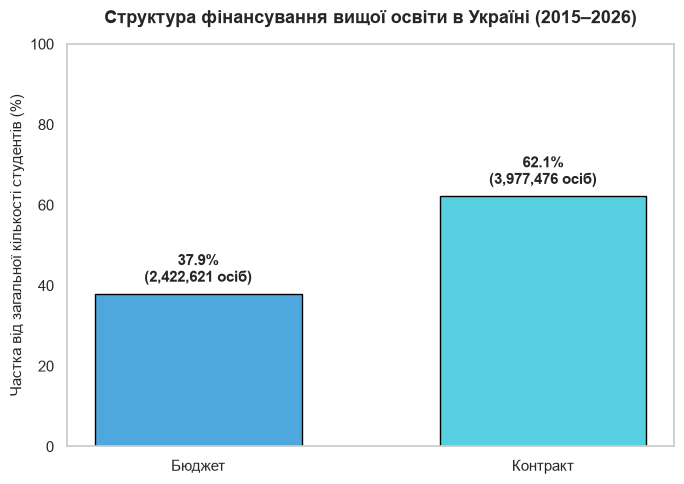

Кількість аналізованих рядків: 289,311
Загальна кількість зарахованих студентів: 6,400,097 осіб


In [3]:
# Рахуємо загальну кількість зарахованих студентів
total_students = df_entrant[[
    'entrant_fulltime_budget',
    'entrant_fulltime_contract',
    'entrant_partime_budget',
    'entrant_partime_contract',
    'entrant_evening_budget',
    'entrant_evening_contract'
]].sum().sum()

# Агрегуємо суми для бюджету та контракту по усіх формах
total_budget = df_entrant[[
    'entrant_fulltime_budget',
    'entrant_partime_budget',
    'entrant_evening_budget'
]].sum().sum()

total_contract = df_entrant[[
    'entrant_fulltime_contract',
    'entrant_partime_contract',
    'entrant_evening_contract'
]].sum().sum()

funding_summary = pd.Series({
    'Бюджет': total_budget,
    'Контракт': total_contract
})

funding_pct = (funding_summary / total_students) * 100

# Будуємо графік фінансування
plt.figure(figsize=(7, 5))
colors = ['#4EA8DE', '#56CFE1']
plt.bar(funding_pct.index, funding_pct.values, color=colors, edgecolor='black', width=0.6)

plt.title('Структура фінансування вищої освіти в Україні (2015–2026)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Частка від загальної кількості студентів (%)', fontsize=11)
plt.ylim(0, 100)
plt.grid(False)

# Додаємо підписи відсотків та кількості людей
for i, (val, people) in enumerate(zip(funding_pct.values, funding_summary.values)):
    plt.text(i, val + 2, f"{val:.1f}%\n({int(people):,} осіб)", ha='center', va='bottom', fontsize=11, fontweight='bold')

# Збереження графіка
plt.tight_layout()
plt.savefig('funding_structure_2015_2026.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Кількість аналізованих рядків: {len(df_entrant):,}")
print(f"Загальна кількість зарахованих студентів: {total_students:,} осіб")

In [4]:
# Агрегуємо кількість зарахованих за роками
yearly_funding = (
    df_entrant
    .groupby('year')[[
        'entrant_fulltime_budget',
        'entrant_fulltime_contract',
        'entrant_partime_budget',
        'entrant_partime_contract',
        'entrant_evening_budget',
        'entrant_evening_contract'
    ]]
    .sum()
)

# Розраховуємо загальну кількість бюджетних і контрактних місць
yearly_funding['Бюджет'] = (
    yearly_funding['entrant_fulltime_budget'] +
    yearly_funding['entrant_partime_budget'] +
    yearly_funding['entrant_evening_budget']
)

yearly_funding['Контракт'] = (
    yearly_funding['entrant_fulltime_contract'] +
    yearly_funding['entrant_partime_contract'] +
    yearly_funding['entrant_evening_contract']
)

yearly_funding['Усього'] = yearly_funding['Бюджет'] + yearly_funding['Контракт']

# Розраховуємо частки фінансування
yearly_funding['Бюджет, %'] = (
    yearly_funding['Бюджет'] / yearly_funding['Усього'] * 100
)

yearly_funding['Контракт, %'] = (
    yearly_funding['Контракт'] / yearly_funding['Усього'] * 100
)

display(yearly_funding[['Бюджет', 'Контракт', 'Усього', 'Бюджет, %', 'Контракт, %']].round(1))

,Бюджет,Контракт,Усього,"Бюджет, %","Контракт, %"
year,,,,,
2015,254655,329788,584443,43.6,56.4
2016,268579,339508,608087,44.2,55.8
2017,219373,339543,558916,39.2,60.8
2018,211105,331973,543078,38.9,61.1
2019,202867,312975,515842,39.3,60.7
2020,192369,287423,479792,40.1,59.9
2021,192083,276985,469068,40.9,59.1
2022,190046,356809,546855,34.8,65.2
2023,180355,418777,599132,30.1,69.9


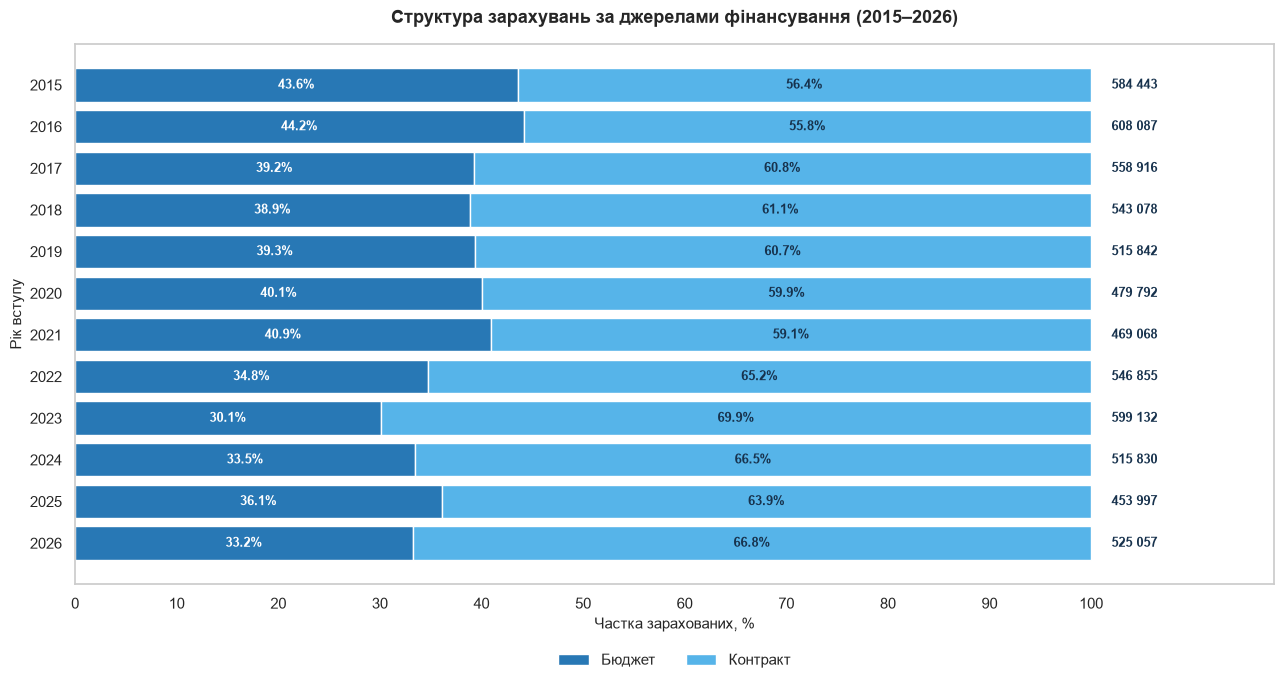

In [5]:
# Структура зарахувань за джерелами фінансування

plt.figure(figsize=(13, 7))

years = yearly_funding.index.astype(str)

plt.barh(
    years,
    yearly_funding['Бюджет, %'],
    color='#2878B5',
    edgecolor='white',
    label='Бюджет'
)

plt.barh(
    years,
    yearly_funding['Контракт, %'],
    left=yearly_funding['Бюджет, %'],
    color='#56B4E9',
    edgecolor='white',
    label='Контракт'
)

# Підписи відсотків усередині сегментів
for i, (budget, contract) in enumerate(
    zip(yearly_funding['Бюджет, %'], yearly_funding['Контракт, %'])
):
    plt.text(
        budget / 2, i,
        f'{budget:.1f}%',
        ha='center', va='center',
        fontsize=9, fontweight='bold', color='white'
    )

    plt.text(
        budget + contract / 2, i,
        f'{contract:.1f}%',
        ha='center', va='center',
        fontsize=9, fontweight='bold', color='#17324D'
    )

# Загальна кількість зарахованих праворуч від смуг
for i, total in enumerate(yearly_funding['Усього']):
    plt.text(
        102, i,
        f'{total:,.0f}'.replace(',', ' '),
        ha='left', va='center',
        fontsize=9, fontweight='bold', color='#17324D'
    )

plt.title(
    'Структура зарахувань за джерелами фінансування (2015–2026)',
    fontsize=13, fontweight='bold', pad=15
)

plt.xlabel('Частка зарахованих, %', fontsize=11)
plt.ylabel('Рік вступу', fontsize=11)

plt.xlim(0, 118)
plt.xticks(range(0, 101, 10))
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)

plt.grid(False)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig('funding_structure_2015_2026.png', dpi=300, bbox_inches='tight')
plt.show()

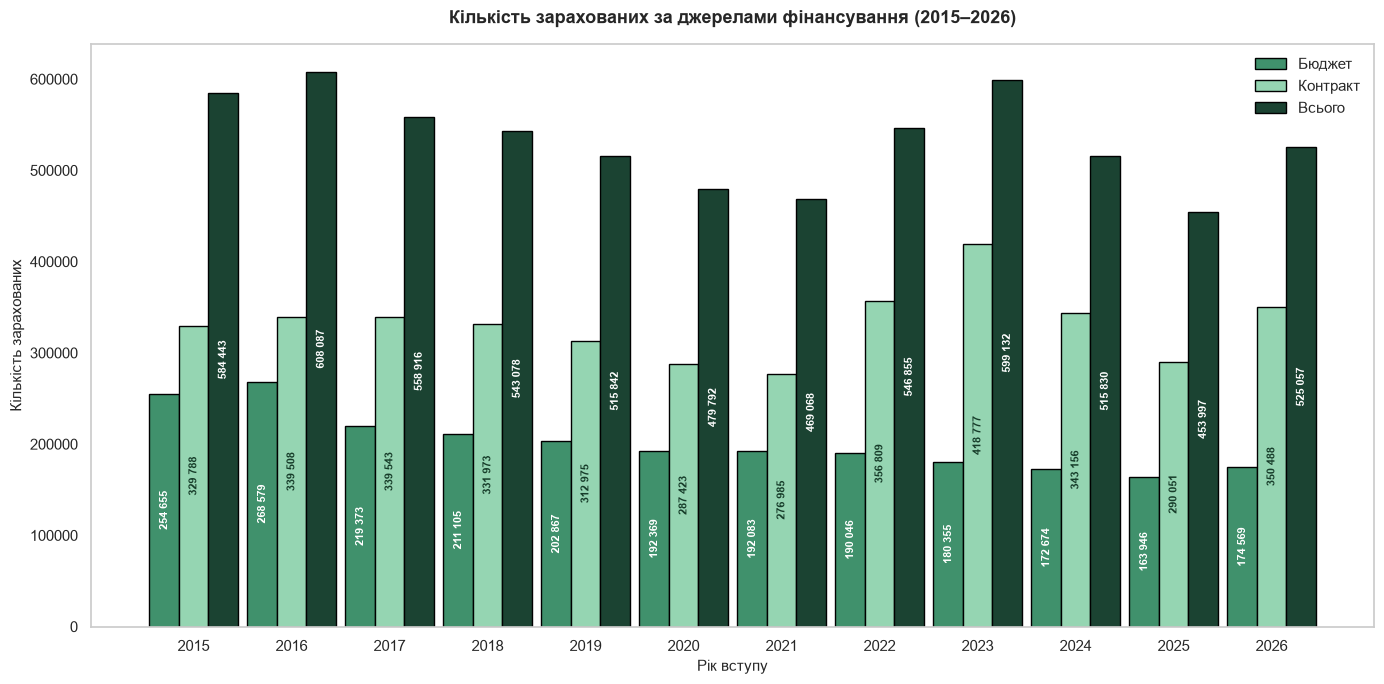

In [6]:
# Зелений графік: бюджет, контракт і загальна кількість зарахованих

plt.figure(figsize=(14, 7))

years = yearly_funding.index.astype(str)
x = range(len(years))
width = 0.30

# Три стовпчики
bars_budget = plt.bar(
    [i - width for i in x],
    yearly_funding['Бюджет'],
    width=width,
    color='#40916C',
    edgecolor='black',
    label='Бюджет'
)

bars_contract = plt.bar(
    list(x),
    yearly_funding['Контракт'],
    width=width,
    color='#95D5B2',
    edgecolor='black',
    label='Контракт'
)

bars_total = plt.bar(
    [i + width for i in x],
    yearly_funding['Усього'],
    width=width,
    color='#1B4332',
    edgecolor='black',
    label='Всього'
)

# Вертикальні підписи всередині стовпчиків
for bars, color in [
    (bars_budget, 'white'),
    (bars_contract, '#173D2A'),
    (bars_total, 'white')
]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height / 2,
            f'{height:,.0f}'.replace(',', ' '),
            ha='center',
            va='center',
            rotation=90,
            fontsize=8,
            fontweight='bold',
            color=color
        )

plt.title(
    'Кількість зарахованих за джерелами фінансування (2015–2026)',
    fontsize=13,
    fontweight='bold',
    pad=15
)

plt.xlabel('Рік вступу', fontsize=11)
plt.ylabel('Кількість зарахованих', fontsize=11)
plt.xticks(list(x), years)
plt.legend(frameon=False)

plt.grid(False)

plt.tight_layout()
plt.savefig('funding_absolute_2015_2026.png', dpi=300, bbox_inches='tight')
plt.show()

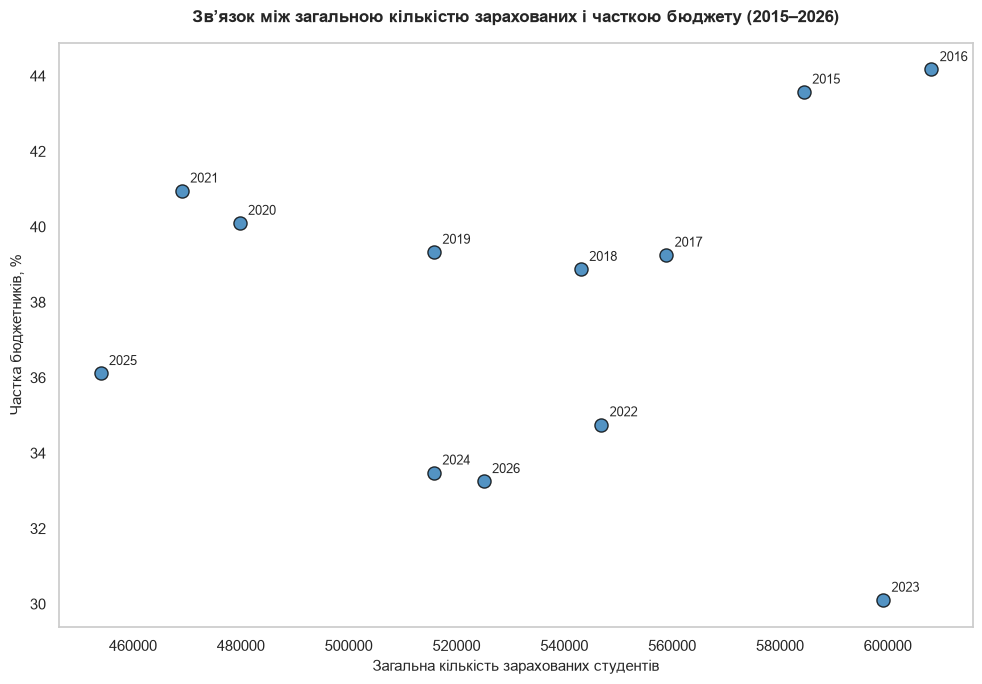

Коефіцієнт кореляції Пірсона: 0.070


In [7]:
# Діаграма розсіювання: загальна кількість зарахованих і частка бюджету

plt.figure(figsize=(10, 7))

plt.scatter(
    yearly_funding['Усього'],
    yearly_funding['Бюджет, %'],
    s=90,
    color='#2878B5',
    edgecolor='black',
    alpha=0.8
)

# Підписи років біля точок
for year, row in yearly_funding.iterrows():
    plt.annotate(
        str(year),
        (row['Усього'], row['Бюджет, %']),
        xytext=(6, 6),
        textcoords='offset points',
        fontsize=9
    )

plt.title(
    'Зв’язок між загальною кількістю зарахованих і часткою бюджету (2015–2026)',
    fontsize=12,
    fontweight='bold',
    pad=15
)

plt.xlabel('Загальна кількість зарахованих студентів', fontsize=11)
plt.ylabel('Частка бюджетників, %', fontsize=11)

plt.grid(False)
plt.tight_layout()
plt.show()

# Коефіцієнт кореляції Пірсона
correlation = yearly_funding['Усього'].corr(
    yearly_funding['Бюджет, %']
)

print(f'Коефіцієнт кореляції Пірсона: {correlation:.3f}')

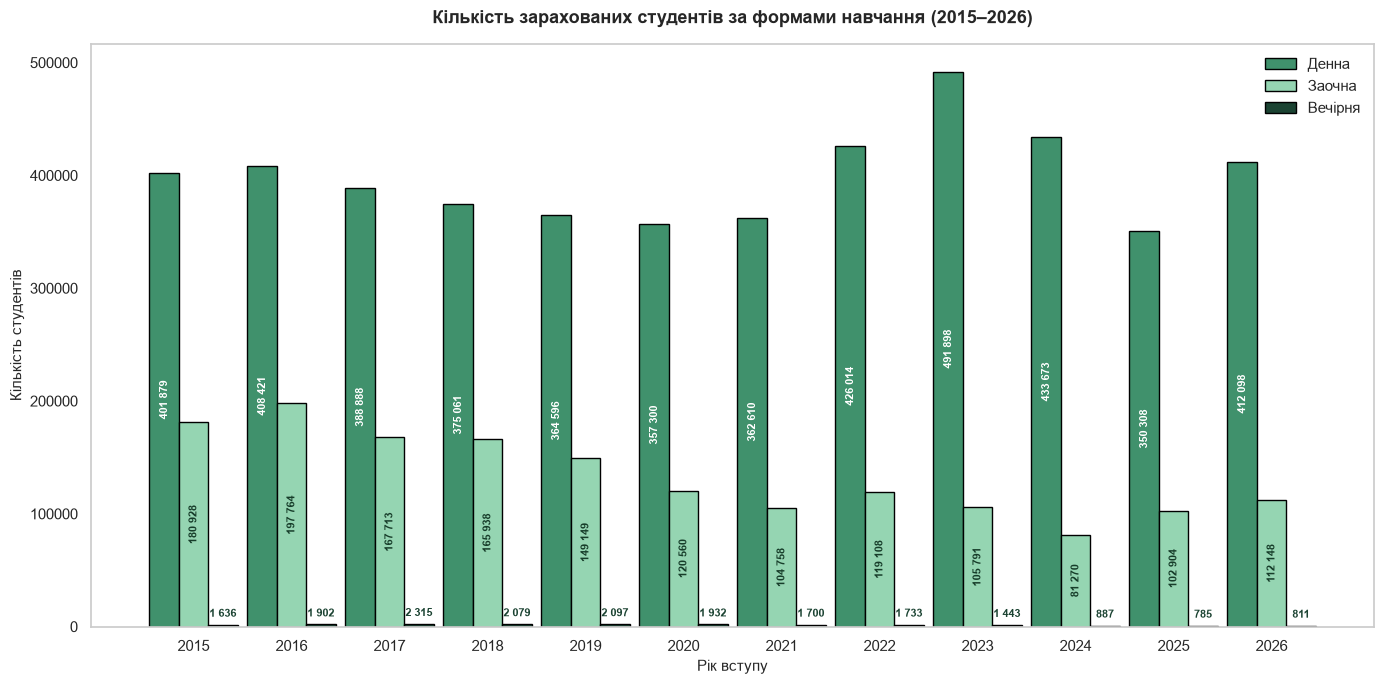

In [8]:
# Кількість зарахованих за формами навчання та роками

yearly_forms = df_entrant.groupby('year')[[
    'entrant_fulltime_budget',
    'entrant_fulltime_contract',
    'entrant_partime_budget',
    'entrant_partime_contract',
    'entrant_evening_budget',
    'entrant_evening_contract'
]].sum()

yearly_forms['Денна'] = (
    yearly_forms['entrant_fulltime_budget'] +
    yearly_forms['entrant_fulltime_contract']
)

yearly_forms['Заочна'] = (
    yearly_forms['entrant_partime_budget'] +
    yearly_forms['entrant_partime_contract']
)

yearly_forms['Вечірня'] = (
    yearly_forms['entrant_evening_budget'] +
    yearly_forms['entrant_evening_contract']
)

# Графік за формами навчання

plt.close('all')
plt.figure(figsize=(14, 7))

years = yearly_forms.index.astype(str)
x = range(len(years))
width = 0.30

bars_day = plt.bar(
    [i - width for i in x],
    yearly_forms['Денна'],
    width=width,
    color='#40916C',
    edgecolor='black',
    label='Денна'
)

bars_extramural = plt.bar(
    list(x),
    yearly_forms['Заочна'],
    width=width,
    color='#95D5B2',
    edgecolor='black',
    label='Заочна'
)

bars_evening = plt.bar(
    [i + width for i in x],
    yearly_forms['Вечірня'],
    width=width,
    color='#1B4332',
    edgecolor='black',
    label='Вечірня'
)

# Вертикальні підписи всередині стовпчиків денної та заочної форм
for bars, color in [
    (bars_day, 'white'),
    (bars_extramural, '#173D2A')
]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height / 2,
            f'{height:,.0f}'.replace(',', ' '),
            ha='center',
            va='center',
            rotation=90,
            fontsize=8,
            fontweight='bold',
            color=color
        )

# Горизонтальні підписи вечірньої форми над стовпчиками
for bar in bars_evening:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5000,
        f'{height:,.0f}'.replace(',', ' '),
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold',
        color='#1B4332'
    )

plt.title(
    'Кількість зарахованих студентів за формами навчання (2015–2026)',
    fontsize=13,
    fontweight='bold',
    pad=15
)

plt.xlabel('Рік вступу', fontsize=11)
plt.ylabel('Кількість студентів', fontsize=11)
plt.xticks(list(x), years)
plt.legend(frameon=False)
plt.grid(False)

plt.tight_layout()
plt.savefig('education_forms_2015_2026.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
# Підготовка даних для загальної регіональної heatmap

df_region = df_entrant.copy()

df_region['region_name_u'] = df_region['region_name_u'].fillna('Не вказано')

budget_cols = [
    'entrant_fulltime_budget',
    'entrant_partime_budget',
    'entrant_evening_budget'
]

contract_cols = [
    'entrant_fulltime_contract',
    'entrant_partime_contract',
    'entrant_evening_contract'
]

df_region['Бюджет'] = df_region[budget_cols].fillna(0).sum(axis=1)

df_region['Контракт'] = df_region[contract_cols].fillna(0).sum(axis=1)

# Агрегація за регіонами та роками
regional_yearly = df_region.groupby(
    ['region_name_u', 'year']
)[['Бюджет', 'Контракт']].sum()

# Окремі матриці фінансування
budget_matrix = regional_yearly['Бюджет'].unstack(fill_value=0)
contract_matrix = regional_yearly['Контракт'].unstack(fill_value=0)

# Сортування регіонів за загальною кількістю зарахованих
region_order = (
    budget_matrix.sum(axis=1) + contract_matrix.sum(axis=1)
).sort_values(ascending=False).index

budget_matrix = budget_matrix.reindex(region_order)
contract_matrix = contract_matrix.reindex(region_order)

# Об'єднання бюджетних і контрактних зарахувань
combined_matrix = pd.concat(
    [budget_matrix, contract_matrix],
    keys=['Бюджет', 'Контракт'],
    names=['Тип фінансування']
).swaplevel(0, 1)

combined_matrix.index.names = ['Регіон', 'Тип фінансування']

row_order = pd.MultiIndex.from_product(
    [region_order, ['Бюджет', 'Контракт']],
    names=['Регіон', 'Тип фінансування']
)

combined_matrix = combined_matrix.reindex(row_order)

print('Матрицю створено успішно!')
print('Розмір:', combined_matrix.shape)
display(combined_matrix.head(6))

Матрицю створено успішно!
Розмір: (54, 12)


year                                  2015   2016   2017   2018   2019   2020  \
Регіон             Тип фінансування                                             
м. Київ            Бюджет            44927  48587  39780  38924  38027  35399   
                   Контракт          70348  74738  75785  75628  72206  69243   
Харківська область Бюджет            26098  27168  21912  21088  20127  19849   
                   Контракт          35211  37676  38960  40213  36119  30879   
Львівська область  Бюджет            20745  21519  18147  17558  16730  16057   
                   Контракт          23997  23136  23430  22748  22372  21479   

year                                  2021   2022   2023   2024   2025   2026  
Регіон             Тип фінансування                                            
м. Київ            Бюджет            35289  34583  32668  30650  28272  29458  
                   Контракт          69155  78047  88930  75259  66782  71603  
Харківська область Бюджет            19756  19197  17079  15812  14705  15562  
                   Контракт          29662  29498  39525  27068  24535  28127  
Львівська область  Бюджет            16363  16429  16550  16168  16094  18119  
                   Контракт          20826  32388  34782  31767  25633  31414

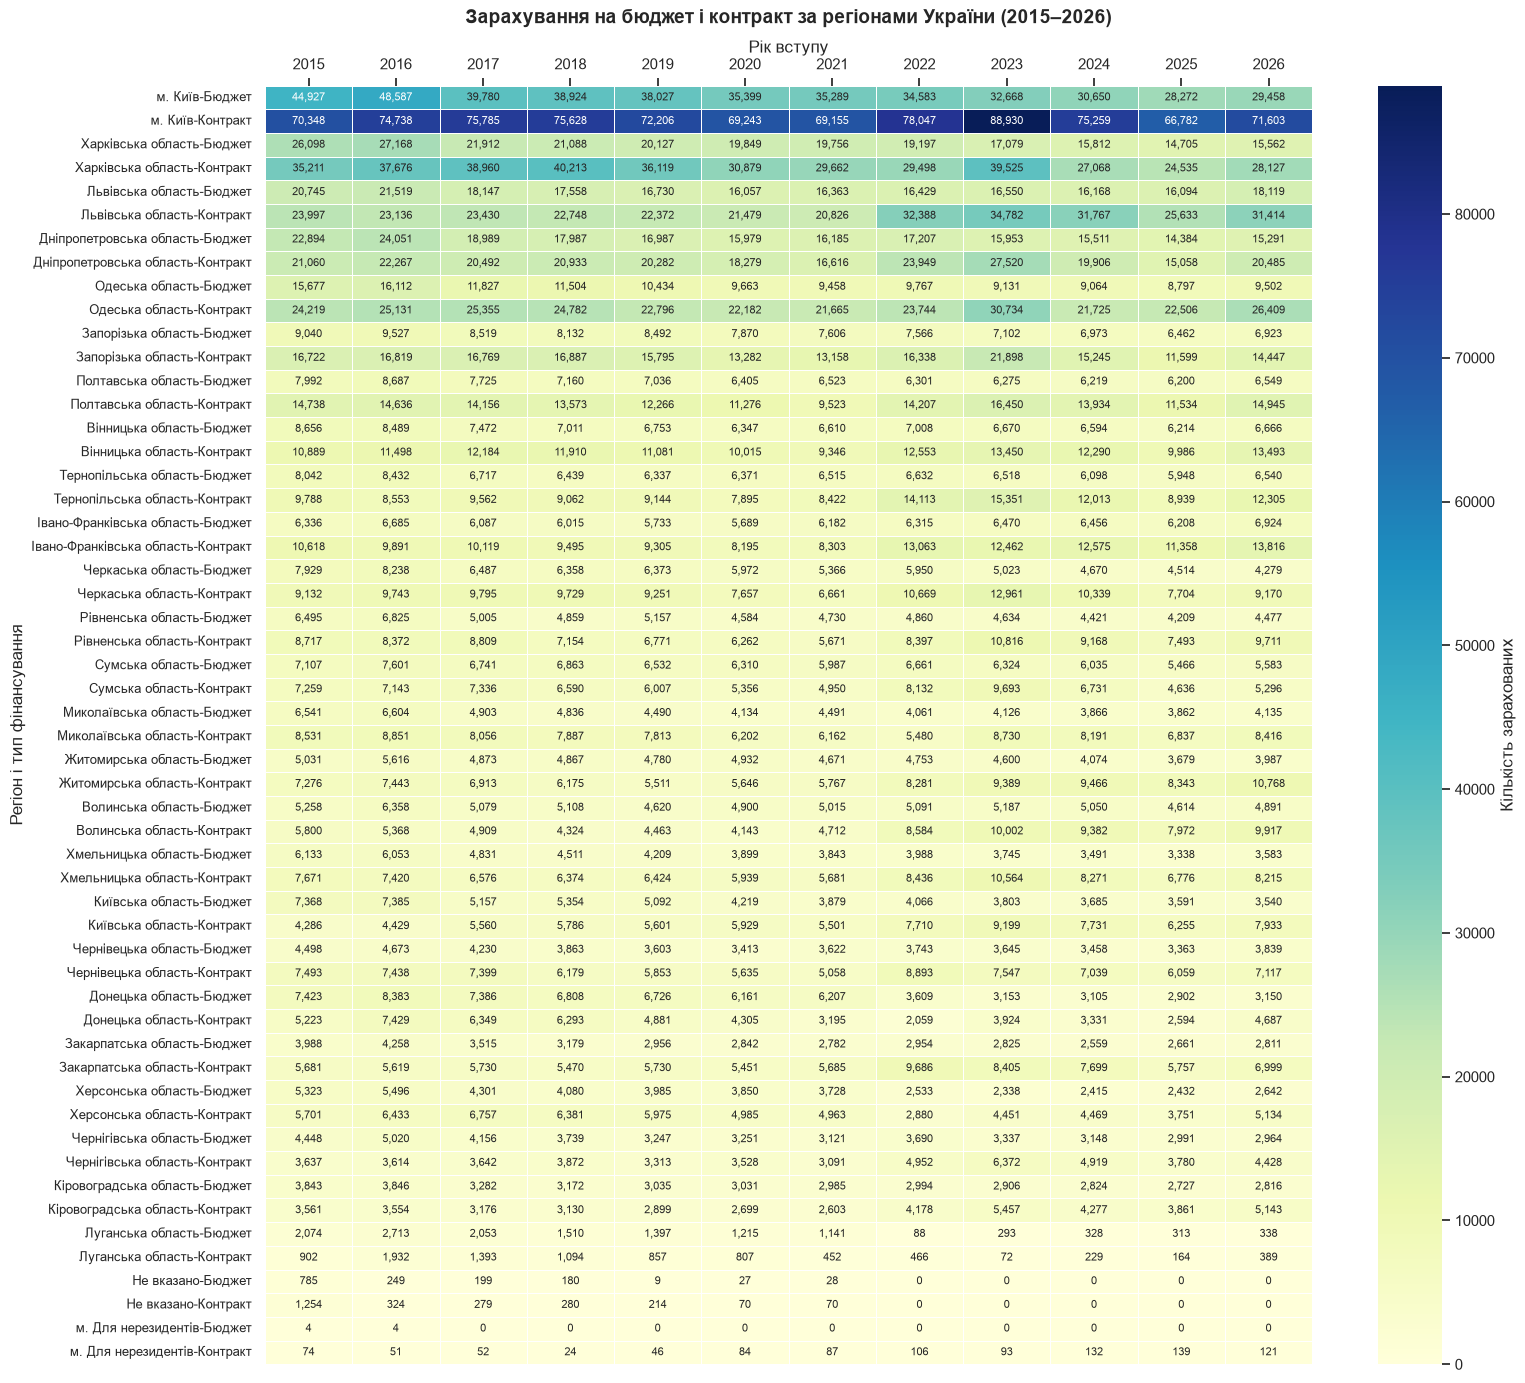

In [10]:
plt.figure(figsize=(16, 14))

ax = sns.heatmap(
    combined_matrix,
    cmap='YlGnBu',
    linewidths=0.4,
    linecolor='white',
    annot=True,
    fmt=',.0f',
    annot_kws={'size': 8},
    cbar_kws={'label': 'Кількість зарахованих'}
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

plt.title(
    'Зарахування на бюджет і контракт за регіонами України (2015–2026)',
    fontsize=14,
    fontweight='bold',
    pad=45
)

plt.xlabel('Рік вступу', fontsize=12)
plt.ylabel('Регіон і тип фінансування', fontsize=12)

plt.xticks(rotation=0, fontsize=11)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig(
    'regional_budget_contract_combined_2015_2026.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

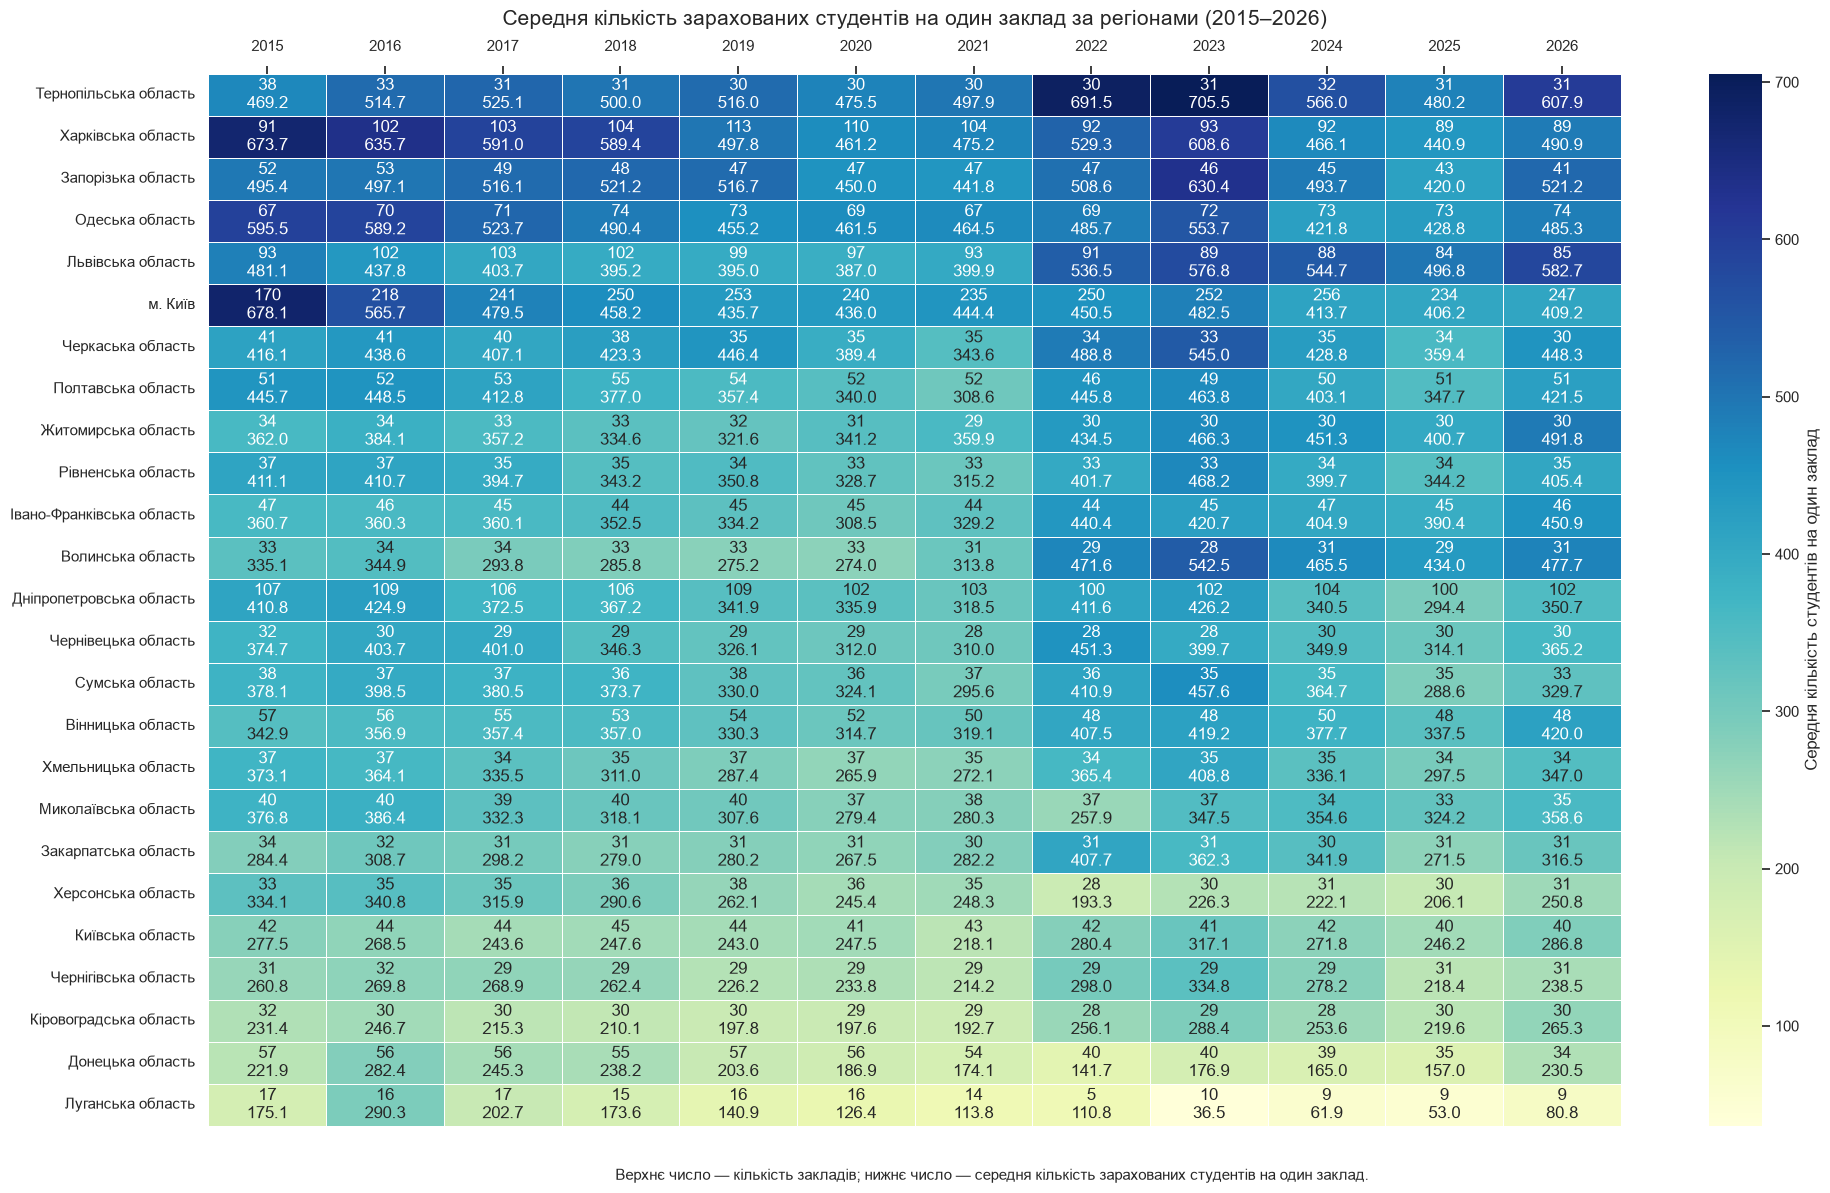

In [11]:
# 1. Створюємо копію даних
df_heat = df_entrant.copy()

# 2. Колонки з кількістю зарахованих студентів
admission_cols = [
    'entrant_fulltime_budget',
    'entrant_partime_budget',
    'entrant_evening_budget',
    'entrant_fulltime_contract',
    'entrant_partime_contract',
    'entrant_evening_contract'
]

# 3. Перетворюємо дані на числовий формат
df_heat['year'] = pd.to_numeric(
    df_heat['year'], errors='coerce'
)

df_heat[admission_cols] = (
    df_heat[admission_cols]
    .apply(pd.to_numeric, errors='coerce')
    .fillna(0)
)

# 4. Розраховуємо загальну кількість зарахованих
df_heat['Загалом'] = df_heat[admission_cols].sum(axis=1)

# 5. Залишаємо 2015–2026 роки та прибираємо категорії резидентів
df_heat = df_heat[
    df_heat['year'].between(2015, 2026)
    & df_heat['region_name_u'].notna()
    & df_heat['university_id'].notna()
    & ~df_heat['region_name_u'].str.contains(
        'резидент', case=False, na=False
    )
].copy()

# 6. Групуємо дані за регіонами та роками
regional_year = (
    df_heat.groupby(['region_name_u', 'year'])
    .agg(
        Закладів=('university_id', 'nunique'),
        Зараховано=('Загалом', 'sum')
    )
    .reset_index()
)

# 7. Розраховуємо середню кількість студентів на один заклад
regional_year['Середнє'] = (
    regional_year['Зараховано'] /
    regional_year['Закладів']
)

# 8. Створюємо матриці середніх значень і кількості закладів
years = list(range(2015, 2027))

avg_matrix = regional_year.pivot(
    index='region_name_u',
    columns='year',
    values='Середнє'
).reindex(columns=years)

count_matrix = regional_year.pivot(
    index='region_name_u',
    columns='year',
    values='Закладів'
).reindex(columns=years)

# 9. Сортуємо регіони за середнім показником за весь період
sort_order = (
    regional_year.groupby('region_name_u')
    .agg(
        Всього=('Зараховано', 'sum'),
        Закладів=('Закладів', 'sum')
    )
)

sort_order['Середнє'] = (
    sort_order['Всього'] /
    sort_order['Закладів']
)

sort_order = sort_order.sort_values(
    'Середнє',
    ascending=False
)

avg_matrix = avg_matrix.reindex(sort_order.index)
count_matrix = count_matrix.reindex(sort_order.index)

# 10. Формуємо підписи клітинок
# Верхнє число — кількість закладів
# Нижнє число — середня кількість студентів

annotations = pd.DataFrame(
    '',
    index=avg_matrix.index,
    columns=avg_matrix.columns
)

for region in avg_matrix.index:
    for year in avg_matrix.columns:

        avg = avg_matrix.loc[region, year]
        count = count_matrix.loc[region, year]

        if pd.notna(avg) and pd.notna(count):
            annotations.loc[region, year] = (
                f'{int(count)}\n{avg:.1f}'
            )

# 11. Будуємо теплову матрицю
plt.figure(figsize=(20, 12))

ax = sns.heatmap(
    avg_matrix,
    annot=annotations,
    fmt='',
    cmap='YlGnBu',
    linewidths=0.5,
    mask=avg_matrix.isna(),
    cbar_kws={
        'label': 'Середня кількість студентів на один заклад'
    }
)

# 12. Оформлення
ax.set_title(
    'Середня кількість зарахованих студентів на один заклад за регіонами (2015–2026)',
    fontsize=15,
    pad=35
)

ax.set_xlabel('')
ax.set_ylabel('')

# Роки зверху
ax.xaxis.tick_top()
ax.tick_params(axis='x', rotation=0, pad=8)
ax.tick_params(axis='y', rotation=0)

# Пояснення до чисел у клітинках
plt.figtext(
    0.5,
    0.01,
    'Верхнє число — кількість закладів; нижнє число — середня кількість зарахованих студентів на один заклад.',
    ha='center',
    fontsize=11
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

In [12]:
# 1. Підрахунок загальної кількості зарахованих за всіма формами навчання
entrant_cols = [
    'entrant_fulltime_budget',
    'entrant_fulltime_contract',
    'entrant_partime_budget',
    'entrant_partime_contract',
    'entrant_evening_budget',
    'entrant_evening_contract'
]
df_entrant['total_enrolled'] = df_entrant[entrant_cols].sum(axis=1)

# 2. Словник уніфікації за НАЗВАМИ спеціальностей
speciality_mapping = {
    'правознавство': 'Право',
    'право': 'Право',

    'менеджмент': 'Менеджмент',
    'менеджмент організацій і адміністрування': 'Менеджмент',

    'психологія': 'Психологія',
    'філологія': 'Філологія',

    'облік і аудит': 'Облік і оподаткування',
    'бухгалтерський облік': 'Облік і оподаткування',
    'облік і оподаткування': 'Облік і оподаткування',

    'будівництво': 'Будівництво та цивільна інженерія',
    'промислове і цивільне будівництво': 'Будівництво та цивільна інженерія',
    'будівництво та експлуатація будівель і споруд': 'Будівництво та цивільна інженерія',
    'будівництво та цивільна інженерія': 'Будівництво та цивільна інженерія',

    'комп’ютерні науки': 'Комп’ютерні науки',
    "комп'ютерні науки": 'Комп’ютерні науки',

    'сестринська справа': 'Медсестринство',
    'медсестринство': 'Медсестринство',

    'електротехніка та електротехнології': 'Електроенергетика, електротехніка та електромеханіка',
    'електромеханіка': 'Електроенергетика, електротехніка та електромеханіка',
    'електроенергетика, електротехніка та електромеханіка': 'Електроенергетика, електротехніка та електромеханіка'
}

# Нормалізуємо назви (прибираємо зайві пробіли, зводимо до нижнього регістру, замінюємо за словником)
df_entrant['speciality_name_analysis'] = (
    df_entrant['speciality_name']
    .astype(str)
    .str.strip()
    .str.lower()
    .map(speciality_mapping)
    .fillna(df_entrant['speciality_name'].astype(str).str.strip())
)

# 3. Уніфікація за КОДАМИ (для галузевих груп і нових літерних кодів ЄДЕБО)
code_clean = df_entrant['speciality_code'].astype(str).str.strip()

# 3.1. Педагогіка та освіта (усі коди 01x, A1-A6 та старі 5.01/6.01/7.01/8.01)
pedagogy_codes = [
    '014', '013', '012', '015', '016', '011',
    'A4', 'A3', 'A2', 'A6', 'A5', 'A1',
    '6.010102', '7.01010201', '5.01010201', '8.01010201',
    '6.010101', '7.01010101', '5.01010101', '8.01010101',
    '6.010104', '5.01010401', '7.01010401', '8.01010401',
    '6.010106', '7.01010601', '5.01010601', '8.01010601',
    '6.010105', '7.01010501', '8.01010501',
    '6.010103', '7.01010301', '5.01010301', '8.01010301',
    '8.18010021', '8.18010022',
    '6.010201', '5.01020101', '7.01020101', '8.01020101'
]
df_entrant.loc[
    code_clean.isin(pedagogy_codes),
    'speciality_name_analysis'
] = 'Педагогіка та освіта'

# 3.2. Електроенергетика (код 141, новий G3 та старі напрями 050701 і 050702)
is_electricity = (
    code_clean.isin(['141', 'G3']) |
    code_clean.str.contains(r'^[5678]\.05070[12]', regex=True)
)
df_entrant.loc[
    is_electricity,
    'speciality_name_analysis'
] = 'Електроенергетика, електротехніка та електромеханіка'

# 3.3. Будівництво та цивільна інженерія (код 192, новий G19 та старі шифри 060101)
is_construction = (
    code_clean.isin(['192', 'G19']) |
    code_clean.str.contains(r'^[5678]\.060101', regex=True)
)
df_entrant.loc[
    is_construction,
    'speciality_name_analysis'
] = 'Будівництво та цивільна інженерія'

# 4. Побудова фінальної зведеної таблиці за ТОП-10 спеціальностями
target_specialities = [
    'Педагогіка та освіта',
    'Право',
    'Менеджмент',
    'Психологія',
    'Облік і оподаткування',
    'Електроенергетика, електротехніка та електромеханіка',
    'Будівництво та цивільна інженерія',
    'Філологія',
    'Медсестринство',
    'Комп’ютерні науки'
]

top10_pivot = (
    df_entrant[df_entrant['speciality_name_analysis'].isin(target_specialities)]
    .pivot_table(
        index='year',
        columns='speciality_name_analysis',
        values='total_enrolled',
        aggfunc='sum',
        fill_value=0
    )
    .astype(int)
)

# Фіксуємо порядок колонок як у вашому запиті
top10_pivot = top10_pivot[target_specialities]
top10_pivot.columns.name = 'speciality_name'

display(top10_pivot)


speciality_name,Педагогіка та освіта,Право,Менеджмент,Психологія,Облік і оподаткування,"Електроенергетика, електротехніка та електромеханіка",Будівництво та цивільна інженерія,Філологія,Медсестринство,Комп’ютерні науки
year,,,,,,,,,,
2015,45872,43459,18100,8527,24766,12353,14418,12936,9061,4686
2016,61845,50637,27610,12855,23884,15805,15377,14869,14823,1766
2017,56265,37742,26458,12707,18256,14237,13862,14668,14049,11198
2018,58069,37018,28805,9510,17417,13256,12263,14952,12205,11193
2019,55201,32158,21391,12481,11446,13507,12403,14258,11575,11654
2020,51181,32093,22232,12350,11152,11169,10679,13724,11425,12845
2021,43242,30357,20846,12749,10291,11694,11401,14025,12823,14376
2022,54274,37340,24636,17609,11271,14671,15241,11939,11870,17296
2023,55710,40165,32116,26019,11494,16414,18528,12894,12960,16271


In [14]:
popular_specialities_analysis = (
    df_entrant
    .groupby('speciality_name_analysis')['total_enrolled']
    .sum()
    .sort_values(ascending=False)
)

display(popular_specialities_analysis.head(15))


speciality_name_analysis
Педагогіка та освіта                                    593886
Право                                                   409489
Менеджмент                                              318879
Психологія                                              208976
Облік і оподаткування                                   174064
Будівництво та цивільна інженерія                       168798
Електроенергетика, електротехніка та електромеханіка    163172
Філологія                                               160827
Медсестринство                                          151474
Комп’ютерні науки                                       140202
Інженерія програмного забезпечення                      123354
Фінанси, банківська справа та страхування               117429
Економіка                                               115939
Харчові технології                                      113217
Медицина                                                112026
Name: total_enrolled, dtype: i

In [16]:
# Загальна кількість зарахованих за кожен рік
total_by_year = (
    df_entrant
    .groupby('year')['total_enrolled']
    .sum()
)

# Частка кожної спеціальності у загальній кількості зарахованих, %
top10_share = (
    top10_pivot
    .div(total_by_year, axis=0)
    .mul(100)
    .round(2)
)

display(
    top10_share.style.format('{:.2f}%')
)


speciality_name,Педагогіка та освіта,Право,Менеджмент,Психологія,Облік і оподаткування,"Електроенергетика, електротехніка та електромеханіка",Будівництво та цивільна інженерія,Філологія,Медсестринство,Комп’ютерні науки
year,,,,,,,,,,
2015,7.85%,7.44%,3.10%,1.46%,4.24%,2.11%,2.47%,2.21%,1.55%,0.80%
2016,10.17%,8.33%,4.54%,2.11%,3.93%,2.60%,2.53%,2.45%,2.44%,0.29%
2017,10.07%,6.75%,4.73%,2.27%,3.27%,2.55%,2.48%,2.62%,2.51%,2.00%
2018,10.69%,6.82%,5.30%,1.75%,3.21%,2.44%,2.26%,2.75%,2.25%,2.06%
2019,10.70%,6.23%,4.15%,2.42%,2.22%,2.62%,2.40%,2.76%,2.24%,2.26%
2020,10.67%,6.69%,4.63%,2.57%,2.32%,2.33%,2.23%,2.86%,2.38%,2.68%
2021,9.22%,6.47%,4.44%,2.72%,2.19%,2.49%,2.43%,2.99%,2.73%,3.06%
2022,9.92%,6.83%,4.51%,3.22%,2.06%,2.68%,2.79%,2.18%,2.17%,3.16%
2023,9.30%,6.70%,5.36%,4.34%,1.92%,2.74%,3.09%,2.15%,2.16%,2.72%


In [17]:
# Порівняння основних показників у 2015 та 2026 роках

comparison = pd.DataFrame({
    '2015': [
        yearly_funding.loc[2015, 'Усього'],
        yearly_funding.loc[2015, 'Бюджет'],
        yearly_funding.loc[2015, 'Контракт'],
        yearly_forms.loc[2015, 'Денна'],
        yearly_forms.loc[2015, 'Заочна'],
        yearly_forms.loc[2015, 'Вечірня']
    ],
    '2026': [
        yearly_funding.loc[2026, 'Усього'],
        yearly_funding.loc[2026, 'Бюджет'],
        yearly_funding.loc[2026, 'Контракт'],
        yearly_forms.loc[2026, 'Денна'],
        yearly_forms.loc[2026, 'Заочна'],
        yearly_forms.loc[2026, 'Вечірня']
    ]
}, index=[
    'Усього зарахованих',
    'Бюджет',
    'Контракт',
    'Денна форма',
    'Заочна форма',
    'Вечірня форма'
])

comparison['Абсолютна зміна'] = comparison['2026'] - comparison['2015']

comparison['Зміна, %'] = (
    (comparison['2026'] / comparison['2015'] - 1) * 100
).round(2)

display(comparison.round(2))

,2015,2026,Абсолютна зміна,"Зміна, %"
Усього зарахованих,584443,525057,-59386,-10.16
Бюджет,254655,174569,-80086,-31.45
Контракт,329788,350488,20700,6.28
Денна форма,401879,412098,10219,2.54
Заочна форма,180928,112148,-68780,-38.02
Вечірня форма,1636,811,-825,-50.43


In [18]:
# Кількість унікальних навчальних закладів за роками
universities_by_year = (
    df_entrant
    .groupby('year')['university_id']
    .nunique()
)

# Загальна кількість зарахованих за роками
students_by_year = (
    df_entrant
    .groupby('year')['total_enrolled']
    .sum()
)

# Середня кількість зарахованих на один навчальний заклад
average_by_year = students_by_year / universities_by_year

# Порівняння 2015 та 2026 років
comparison_universities = pd.DataFrame({
    '2015': [
        universities_by_year.loc[2015],
        students_by_year.loc[2015],
        average_by_year.loc[2015]
    ],
    '2026': [
        universities_by_year.loc[2026],
        students_by_year.loc[2026],
        average_by_year.loc[2026]
    ]
}, index=[
    'Кількість НЗ',
    'Усього зарахованих',
    'Середня кількість на один НЗ'
])

comparison_universities['Абсолютна зміна'] = (
    comparison_universities['2026'] - comparison_universities['2015']
)

comparison_universities['Зміна, %'] = (
    (comparison_universities['2026'] /
     comparison_universities['2015'] - 1) * 100
).round(2)

display(comparison_universities.round(2))

,2015,2026,Абсолютна зміна,"Зміна, %"
Кількість НЗ,1325.00,1279.00,-46.00,-3.47
Усього зарахованих,584443.00,525057.00,-59386.00,-10.16
Середня кількість на один НЗ,441.09,410.52,-30.57,-6.93


In [19]:
# Залишаємо записи з реальним зарахуванням (щоб виключити порожні заявки)
active_entrants = df_entrant[df_entrant['total_enrolled'] > 0]

# 1. Кількість унікальних НЗ за роками
universities_by_year = (
    active_entrants
    .groupby('year')['university_id']
    .nunique()
)

# 2. Загальна кількість зарахованих за роками
students_by_year = (
    active_entrants
    .groupby('year')['total_enrolled']
    .sum()
)

# 3. Середня кількість зарахованих на один навчальний заклад
average_by_year = students_by_year / universities_by_year

# 4. Порівняння 2015 та 2026 років
comparison_universities = pd.DataFrame({
    '2015': [
        universities_by_year.loc[2015],
        students_by_year.loc[2015],
        average_by_year.loc[2015]
    ],
    '2026': [
        universities_by_year.loc[2026],
        students_by_year.loc[2026],
        average_by_year.loc[2026]
    ]
}, index=[
    'Кількість НЗ',
    'Усього зарахованих',
    'Середня кількість на один НЗ'
])

comparison_universities['Абсолютна зміна'] = (
    comparison_universities['2026'] - comparison_universities['2015']
)

comparison_universities['Зміна, %'] = (
    (comparison_universities['2026'] / comparison_universities['2015'] - 1) * 100
).round(2)

# Акуратне відображення (цілі числа для кількості та 2 знаки для середнього і %)
display(
    comparison_universities.style.format({
        '2015': lambda x: f'{x:,.0f}' if x >= 1000 or x.is_integer() else f'{x:,.2f}',
        '2026': lambda x: f'{x:,.0f}' if x >= 1000 or x.is_integer() else f'{x:,.2f}',
        'Абсолютна зміна': lambda x: f'{x:+,.0f}' if abs(x) >= 1000 or x.is_integer() else f'{x:+,.2f}',
        'Зміна, %': '{:+.2f}%'
    })
)


,2015,2026,Абсолютна зміна,"Зміна, %"
Кількість НЗ,"1,325","1,276",-49,-3.70%
Усього зарахованих,"584,443","525,057","-59,386",-10.16%
Середня кількість на один НЗ,441.09,411.49,-29.60,-6.71%
